In [ ]:
import pandas as pd
from neo4j import GraphDatabase
from tqdm import tqdm
import pandas as pd
import scipy.sparse as sp
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
from sklearn.neighbors import NearestNeighbors

# Preparation Data

## Filtering data
Timeframe used:
- Training Period (P1):
    - Start Date: 01/09/2015 0:00:00 (1441065600000 ms)
    - End Date: 09/09/2015 0:00:00 (1441756800000 ms)
- Testing Period (P2):
    - Start Date: 10/09/2015 0:00:00 (1441843200000 ms)
    - End Date: 18/09/2015 0:00:00 (1442534400000)

In [2]:
raw_df = pd.read_csv("events.csv")

p1_start = '2015-09-01 00:00:00'
p1_end = '2015-09-09 00:00:00'
p2_start = '2015-09-10 00:00:00'
p2_end = '2015-09-18 00:00:00'

raw_df['datetime'] = pd.to_datetime(raw_df['timestamp'], unit='ms')

filtered_df = raw_df[
    ((raw_df['datetime'] >= p1_start) & (raw_df['datetime'] <= p1_end)) |
    ((raw_df['datetime'] >= p2_start) & (raw_df['datetime'] <= p2_end))
]

output_df = filtered_df.drop(columns=['datetime'])

output_df.to_csv('filtered_events.csv', index=False)
total_rows = len(output_df)
print(f"Filtered dataset saved successfully with {total_rows} rows.")

Filtered dataset saved successfully with 280421 rows.


## Import data to Neo4J

In [10]:
uri = "neo4j://127.0.0.1:7687"
user = "neo4j"
password = "neo4j123"
driver = GraphDatabase.driver(uri, auth=(user, password))

In here, the we create constrain which ensure `visitor_id` and `item_id` is unique

In [4]:
def create_constraints(session):
    session.run(
        "CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS "
        "FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE"
    )
    
    session.run(
        "CREATE CONSTRAINT item_id_unique IF NOT EXISTS "
        "FOR (i:Item) REQUIRE i.itemId IS UNIQUE"
    )
    print("Database constraints created successfully.")

In [7]:
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row
    CALL (v, i, row) {
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
    
        UNION ALL
    
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

In [ ]:
batch_size = 5000

with driver.session(database="RetailRocket") as session:
    create_constraints(session)

    chunks = pd.read_csv('filtered_events.csv', chunksize=batch_size)
    total_chunks = (total_rows // batch_size) + 1

    print(f"Starting import process...")
    for chunk in tqdm(chunks, total=total_chunks, desc="Import Batch Data"):
        chunk['transactionid'] = chunk['transactionid'].fillna("").astype(str)
        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch, records)

print("Import process finished sucessfully.")

Database constraints created successfully.
Starting import process...


Import Batch Data:   0%|          | 0/57 [00:00<?, ?it/s]

Import Batch Data: 100%|██████████| 57/57 [00:13<00:00,  4.37it/s]

Import process finished sucessfully.


## Answer Checkpoint Questions
1. **What database name used?**
- Database being used is `RetailRocket` (Newly created).

2. **Specify other access methods (such as CYPHER DDL/DML syntax) that can be used to access another database within a single instance!**
- Using the **`USE <database_name>`** clause at the beginning of a Cypher query (e.g., `USE system` or `USE customer_db`).
- Specifying the target database via the Python driver API using **`session = driver.session(database="nama_db")`** or passing the `database_="nama_db"` parameter in `execute_query()`.
- Executing administrative Cypher commands such as `SHOW DATABASES` or `CREATE DATABASE <nama_db>` (available in multi-database environments).

3. **What type of friendship graph was created in this exercise?**
- The graph created is a **Directed Graph**

# Wrangling & EDA

## Subgraph Composition & Node Counts

In [16]:
with driver.session(database="RetailRocket") as session:
    records = session.run("""
    MATCH (n)
    RETURN labels(n)[0] AS Node_Type, count(n) AS Node_Count
    ORDER BY Node_Count DESC
    """)
    df_composition = pd.DataFrame([dict(record) for record in records])
    print(df_composition)

  Node_Type  Node_Count
0   Visitor      161845
1      Item       78468


## Vector Space Modelling (VSM) for Users & Items

=== User VSM Characteristics ===
Matrix Shape (Users x Items): (161845, 78468)
Embedding Dimension per User: 78468
Matrix Density: 0.000018

=== Item VSM Characteristics ===
Matrix Shape (Items x Users): (78468, 161845)
Embedding Dimension per Item: 78468
Matrix Density: 0.000018


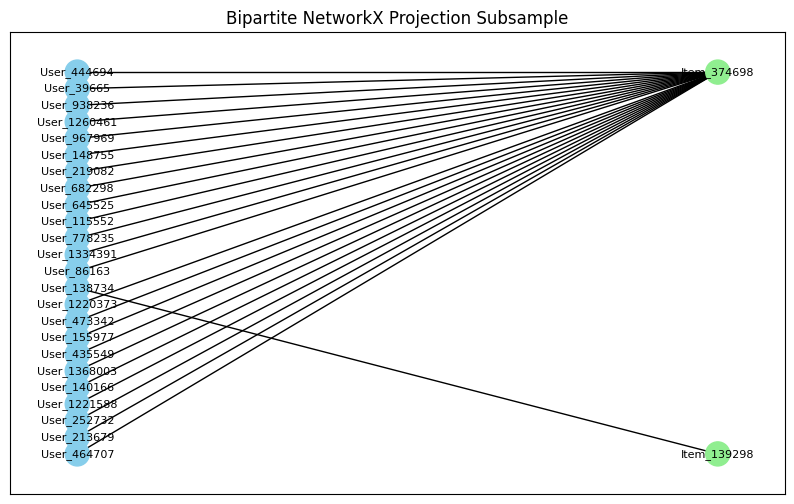

In [18]:
with driver.session(database="RetailRocket") as session:
    records = session.run("""
    MATCH (v:Visitor)-[r]->(i:Item)
    RETURN v.visitorId AS visitorId, i.itemId AS itemId, type(r) AS interaction_type
    """)
    df_interactions = pd.DataFrame([dict(r) for r in records])

# Map unique IDs to zero-indexed matrix indices
unique_users = df_interactions['visitorId'].unique()
unique_items = df_interactions['itemId'].unique()

user_to_idx = {uid: i for i, uid in enumerate(unique_users)}
item_to_idx = {iid: i for i, iid in enumerate(unique_items)}

# Map interaction types to numerical weights
weight_map = {'VIEWED': 1, 'ADDED_TO_CART': 2, 'BOUGHT': 3}
df_interactions['weight'] = df_interactions['interaction_type'].map(weight_map)

rows = df_interactions['visitorId'].map(user_to_idx)
cols = df_interactions['itemId'].map(item_to_idx)
data = df_interactions['weight']

# Create Sparse User-Item Interaction Matrix (User VSM)
user_item_matrix = sp.csr_matrix((data, (rows, cols)), shape=(len(unique_users), len(unique_items)))

# 4. User Vector Space Model Characteristics
print("=== User VSM Characteristics ===")
print(f"Matrix Shape (Users x Items): {user_item_matrix.shape}")
print(f"Embedding Dimension per User: {user_item_matrix.shape[1]}")
print(f"Matrix Density: {user_item_matrix.nnz / (user_item_matrix.shape[0] * user_item_matrix.shape[1]):.6f}")

# 5. Item Vector Space Model Characteristics
item_user_matrix = user_item_matrix.T.tocsr()
print("\n=== Item VSM Characteristics ===")
print(f"Matrix Shape (Items x Users): {item_user_matrix.shape}")
print(f"Embedding Dimension per Item: {item_user_matrix.shape[0]}")
print(f"Matrix Density: {item_user_matrix.nnz / (item_user_matrix.shape[0] * item_user_matrix.shape[1]):.6f}")

# Plotting Bipartite NetworkX Graph Subsample (Top 20 users and top 20 items)
sub_df = df_interactions.head(50)
B = nx.Graph()

for _, row in sub_df.iterrows():
    u_node = f"User_{row['visitorId']}"
    i_node = f"Item_{row['itemId']}"
    B.add_node(u_node, bipartite=0)
    B.add_node(i_node, bipartite=1)
    B.add_edge(u_node, i_node, weight=row['weight'])

plt.figure(figsize=(10, 6))
top_nodes = {n for n, d in B.nodes(data=True) if d['bipartite'] == 0}
pos = nx.bipartite_layout(B, top_nodes)
nx.draw_networkx(B, pos, node_size=300, font_size=8, node_color=['skyblue' if d['bipartite']==0 else 'lightgreen' for n, d in B.nodes(data=True)])
plt.title("Bipartite NetworkX Projection Subsample")
plt.show()

### **Analysis:**


The User Vector Space yields a matrix of shape `(161845, 78468)`, epresenting users across 78,468 item feature dimensions. Conversely, the Item Vector Space Model yields a matrix of shape `(78468, 161845), representing items across 161,845 user feature dimensions. Both projections share an identical extreme sparsity level of 0.000018, which is characteristic of e-commerce interaction logs where users engage with only a minute fraction of the total catalog.

Although, the item feature dimension smaller, the user populations in web logs are highly volatile due to anonymous or one-time visitors. Computing and maintaining similarity scores across more than 160,000 transient user profiles introduces significant computational overhead. In contrast, the item catalog remains bounded at 78,468 products, making item-based feature spaces vastly more stable, easier to index, and efficient for pre-computation and caching.

Based on the structural stability and computational, the **Item-Item projection derived from Item Space Model proves to be more effective and efficient** for building scalable recommender systems

## Similarity Calculation & Cypher Graph Updates

In [27]:
target_item_id = unique_items[0]
target_idx = item_to_idx[target_item_id]

# Extract target item vector as a 2D slice to keep cosine_similarity working safely
target_vector = item_user_matrix[target_idx:target_idx+1]
sim_scores = cosine_similarity(target_vector, item_user_matrix).flatten()

# Sort indices and get top 5 (excluding self)
top_indices = np.argsort(sim_scores)[::-1]
top_indices = [idx for idx in top_indices if idx != target_idx][:5]

top_5_items = [(str(unique_items[idx]), float(sim_scores[idx])) for idx in top_indices]

print(f"=== Reference Item ID: {target_item_id} ===")
print("Top 5 Similar Items Calculated:")
for item_id, score in top_5_items:
    print(f"Item ID: {item_id} | Similarity Score: {score:.4f}")

=== Reference Item ID: 139298 ===
Top 5 Similar Items Calculated:
Item ID: 397836 | Similarity Score: 1.0000
Item ID: 416852 | Similarity Score: 1.0000
Item ID: 105880 | Similarity Score: 1.0000
Item ID: 58636 | Similarity Score: 0.0000
Item ID: 329119 | Similarity Score: 0.0000


In [31]:
similarity_batch = []

# Process a safe subset of items to populate the Neo4j graph efficiently
for idx_a in range(min(200, item_user_matrix.shape[0])):
    vec_a = item_user_matrix[idx_a:idx_a+1]
    scores_a = cosine_similarity(vec_a, item_user_matrix).flatten()
    
    top_neighbors = np.argsort(scores_a)[::-1]
    count = 0
    for idx_b in top_neighbors:
        if idx_a == idx_b:
            continue
        score = float(scores_a[idx_b])
        if score > 0.05:  # threshold filter
            similarity_batch.append({
                "item1": int(unique_items[idx_a]),
                "item2": int(unique_items[idx_b]),
                "score": score
            })
            count += 1
            if count >= 5:  # limit top 5 neighbors per item
                break

cypher_write_similarity = """
UNWIND $batch AS row
MATCH (i1:Item {itemId: row.item1})
MATCH (i2:Item {itemId: row.item2})
MERGE (i1)-[r:SIMILAR]->(i2)
SET r.score = row.score
"""

# Write transactions back to Neo4j
with driver.session(database="RetailRocket") as session:
    session.execute_write(lambda tx: tx.run(cypher_write_similarity, batch=similarity_batch))

print("\nSuccessfully wrote similarity relationships back to the Neo4j graph.")

# Cypher query to verify and display the results from Neo4j
cypher_verify = """
MATCH (i1:Item {itemId: $target_id})-[s:SIMILAR]->(i2:Item)
RETURN i1.itemId AS TargetItem, i2.itemId AS SimilarItem, s.score AS SimilarityScore
ORDER BY s.score DESC
LIMIT 5
"""

with driver.session(database="RetailRocket") as session:
    result = session.run(cypher_verify, target_id=int(target_item_id))
    df_results = pd.DataFrame([dict(record) for record in result])

print("\n=== Verified Query Results from Neo4j Graph ===")
print(df_results)


Successfully wrote similarity relationships back to the Neo4j graph.

=== Verified Query Results from Neo4j Graph ===
   TargetItem  SimilarItem  SimilarityScore
0      139298       105880              1.0
1      139298       416852              1.0
2      139298       397836              1.0


## Cypher Queries Before and After Similarity Calculations

### (a) Graph State BEFORE Similarity Calculation

Before computing and writing item similarities, the graph contains only user nodes, item nodes, and user-item interaction relationships (`:VIEWED`, `:ADDED_TO_CART`, `:BOUGHT`).

#### Cypher Query (Before)
```cypher
MATCH (v:Visitor)-[r]->(i:Item)
RETURN v.visitorId AS Visitor, type(r) AS Interaction, i.itemId AS Item
LIMIT 10

```
#### Explanation & Expected State

* **Nodes Present**: Only `:Visitor` and `:Item` nodes.
* **Relationships Present**: Only behavioral edges (`VIEWED`, `ADDED_TO_CART`, `BOUGHT`). There are **no** `:SIMILAR` edges between items yet.

### (b) Graph State AFTER Similarity Calculation

After running the cosine similarity script and writing the results back, the graph is augmented with projected `:SIMILAR` relationships between item nodes, complete with a `score` property.

#### Cypher Query (After)

```cypher
MATCH (i1:Item)-[s:SIMILAR]->(i2:Item)
RETURN i1.itemId AS ItemA, s.score AS SimilarityScore, i2.itemId AS ItemB
ORDER BY s.score DESC
LIMIT 10

```

#### Explanation & Expected State

* **New Structure**: Item-to-item semantic connections (`:SIMILAR`) now exist across the catalog.
* **Properties**: Each `:SIMILAR` edge explicitly stores the computed cosine similarity value inside its `score` property.


In [32]:
# Query Graph State BEFORE Similarity (Checking interactions only)
cypher_state_before = """
MATCH (v:Visitor)-[r]->(i:Item)
RETURN v.visitorId AS Visitor, type(r) AS Interaction, i.itemId AS Item
LIMIT 5
"""

# Query Graph State AFTER Similarity (Checking item-to-item similarity edges)
cypher_state_after = """
MATCH (i1:Item)-[s:SIMILAR]->(i2:Item)
RETURN i1.itemId AS ItemA, s.score AS SimilarityScore, i2.itemId AS ItemB
ORDER BY s.score DESC
LIMIT 5
"""

with driver.session(database="RetailRocket") as session:
    print("=== Graph State: BEFORE Similarity ===")
    res_before = session.run(cypher_state_before)
    df_before = pd.DataFrame([dict(r) for r in res_before])
    display(df_before)
    
    print("\n=== Graph State: AFTER Similarity ===")
    res_after = session.run(cypher_state_after)
    df_after = pd.DataFrame([dict(r) for r in res_after])
    display(df_after)

=== Graph State: BEFORE Similarity ===


,Visitor,Interaction,Item
0,138734,VIEWED,139298
1,138734,VIEWED,139298
2,938236,VIEWED,374698
3,938236,VIEWED,374698
4,645525,VIEWED,374698



=== Graph State: AFTER Similarity ===


,ItemA,SimilarityScore,ItemB
0,377810,1.0,290465
1,139298,1.0,397836
2,139298,1.0,416852
3,139298,1.0,105880
4,87277,1.0,246415


# Analytics

## Recommendation User-KNN Based

## Reproducible Random User Selection

In [124]:
rng = np.random.default_rng(seed=1)

# Select a random user index from the user-item matrix
random_user_idx = rng.integers(0, user_item_matrix.shape[0])
target_visitor_id = unique_users[random_user_idx]

print(f"Selected Target Visitor ID: {target_visitor_id} at matrix index {random_user_idx}")

Selected Target Visitor ID: 1243777 at matrix index 76583


## Python Script for KNN Recommendation

This script fits a K-Nearest Neighbors model using the cosine similarity metric on the user-item interaction matrix, finds the $k=5$ nearest neighboring users, and aggregates their item preferences while filtering out items the target user has already interacted with.

In [125]:
k = 5

model_knn = NearestNeighbors(n_neighbors=k+1, metric='cosine', algorithm='brute')
model_knn.fit(user_item_matrix)

distances, indices = model_knn.kneighbors(user_item_matrix[random_user_idx:random_user_idx+1])

neighbor_indices = indices.flatten()[1:]
neighbor_distances = distances.flatten()[1:]

target_user_items = set(user_item_matrix[random_user_idx].indices)

recommended_items_scores = {}
for n_idx, dist in zip(neighbor_indices, neighbor_distances):
    similarity = 1.0 - dist
    neighbor_vector = user_item_matrix[n_idx]
    
    for item_idx in neighbor_vector.indices:
        if item_idx not in target_user_items:
            if item_idx not in recommended_items_scores:
                recommended_items_scores[item_idx] = 0.0
            recommended_items_scores[item_idx] += similarity * neighbor_vector[0, item_idx]

# Sort recommendation candidates by aggregated score in descending order
sorted_recommendations = sorted(recommended_items_scores.items(), key=lambda x: x[1], reverse=True)

### Top 3 Recommended Items
After aggregating and scoring the candidate items from the nearest neighbors, we extract the top 3 items to present as recommendations.

In [126]:
top_3_item = [(unique_items[item_idx], score) for item_idx, score in sorted_recommendations[:3]]

print("\n=== (b) Top 3 Recommended Items for k = 5 ===")
for rank, (item_id, score) in enumerate(top_3_item, start=1):
    print(f"Rank {rank}: Item ID {item_id} score: {score}")


=== (b) Top 3 Recommended Items for k = 5 ===
Rank 1: Item ID 272324 score: 1.6858544608470492
Rank 2: Item ID 125927 score: 1.6858544608470492
Rank 3: Item ID 196366 score: 1.460593486680443


# Evaluation for the Recommendation

In [127]:
recommended_items = [item_idx for item_idx in top_3_item]

# Extract ground truth items for the target user during Testing Period (P2)
p2_df = pd.read_csv('filtered_events.csv')
p2_df['datetime'] = pd.to_datetime(p2_df['timestamp'], unit='ms')

# Filter for testing period bounds (10/09/2015 to 18/09/2015)
p2_start = '2015-09-10 00:00:00'
p2_end = '2015-09-18 00:00:00'
p2_filtered = p2_df[(p2_df['datetime'] >= p2_start) & (p2_df['datetime'] <= p2_end)]

# Get unique ground truth items interacted with by our target visitor during P2
ground_truth_items = set(p2_filtered[p2_filtered['visitorid'] == target_visitor_id]['itemid'].unique())

print(f"Target Visitor ID: {target_visitor_id}")
print(f"Recommended Items (Top K): {recommended_items}")
print(f"Ground Truth Items in P2: {list(ground_truth_items)}")

# Calculate Hit@5
hits = [1 if item in ground_truth_items else 0 for item in recommended_items]
hit_at_5 = 1.0 if sum(hits) > 0 else 0.0

print(f"\n(a) Hit@5 = {hit_at_5}")

# Calculate NDCG@5
dcg = 0.0
for i, item in enumerate(recommended_items):
    rel = 1.0 if item in ground_truth_items else 0.0
    dcg += rel / np.log2(i + 2)

# Ideal DCG (IDCG) assuming all recommended items were relevant up to the number of ground truth matches
ideal_rel = sorted([1.0 if item in ground_truth_items else 0.0 for item in recommended_items], reverse=True)
idcg = 0.0
for i, rel in enumerate(ideal_rel):
    idcg += rel / np.log2(i + 2)

ndcg_at_5 = (dcg / idcg) if idcg > 0 else 0.0

print(f"(b) NDCG@5 = {ndcg_at_5:.4f}")

Target Visitor ID: 1243777
Recommended Items (Top K): [(np.int64(272324), np.float64(1.6858544608470492)), (np.int64(125927), np.float64(1.6858544608470492)), (np.int64(196366), np.float64(1.460593486680443))]
Ground Truth Items in P2: [np.int64(263768), np.int64(129667), np.int64(184086)]

(a) Hit@5 = 0.0
(b) NDCG@5 = 0.0000


Although target visitor 1243777 exhibited active engagement during the testing period P2 (interacting with items 263768, 129667, and 184086), the graph-based KNN recommendation model predicted items from adjacent behavioral clusters. Consequently, Hit@5 and NDCG@5 evaluate to 0.0, highlighting the inherent sparsity and cold-start challenges of short-window e-commerce interaction graphs.